# LIBS spectra at 300 / 350 / 400 °C: full spectrum and zoomed window

Based on `cerium.ipynb`. For each of the four samples (Ce 1 wt.%, Ce 5 wt.%, Gd 1 wt.%, Gd 5 wt.%) the three temperatures are overlaid:

* **4 full-spectrum plots** (200–1000 nm, one per sample)
* **4 zoomed plots** (Ce: 390–480 nm, same window as `cerium.ipynb`; Gd: 400–435 nm)

The spectra are **not baseline-subtracted, smoothed or normalised to a peak**. The only processing is putting every file on a *counts-per-shot* scale, so that accumulated and single-shot files can be overlaid: accumulated spectra are divided by the number of shots, and files that store several single-shot spectra are averaged.

Images are also saved to `output/spectra_overlays/`.

In [1]:
import warnings
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

from src.LIBS.tdms_loader import LoadLIBSData
from src.LIBS import normalization as nz

# ---------------- configuration ----------------
DATA = Path('data/libs_data/Conference_Data')
SAMPLES = {   # key -> (folder, plot title)
    'Ce_1': (DATA / 'Ce/Ce_1', 'Cerium (1 wt.%)'),
    'Ce_5': (DATA / 'Ce/Ce_5', 'Cerium (5 wt.%)'),
    'Gd_1': (DATA / 'Gd/Gd_1', 'Gadolinium (1 wt.%)'),
    'Gd_5': (DATA / 'Gd/Gd_5', 'Gadolinium (5 wt.%)'),
}

# Zoom window (nm) per element.
WINDOW = {'Ce': (390, 480), 'Gd': (400, 435)}
FULL_RANGE = (200, 1000)

# Gd_5 300 C: only Grid Location # 1-1 belongs to this experiment (3.5 us, 80 mJ, 5 shots);
# the other 10 spectra in that file were recorded with different settings and are excluded.
COLUMNS = {('Gd_5', 300): ['Grid Location # 1-1']}

COLORS = {300: '#1f5fa8', 350: '#10b110', 400: '#e60707'}   # same colours as cerium.ipynb
OUT = Path('output/spectra_overlays'); OUT.mkdir(parents=True, exist_ok=True)

## Load (counts per shot)

In [2]:
spectra, wavelengths = {}, None
for sample, (folder, title) in SAMPLES.items():
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')   # Gd_5 300 C warns about its mixed columns; handled by COLUMNS
        loader = LoadLIBSData(folder)
    spectra[sample] = {}
    for name, f in loader.items():
        T = nz.temperature_from_name(name)
        cols = COLUMNS.get((sample, T))
        spectra[sample][T] = nz.per_shot_spectrum(f, cols)
        wavelengths = f.wavelengths if wavelengths is None else wavelengths
        n_used = len(cols) if cols else f.spectra.shape[1]
        print(f'{sample} {T} C: {name}: {n_used} of {f.spectra.shape[1]} spectra used, '
              f'{"accumulated over " + str(int(f.params["Number Of Shots"])) + " shots" if f.accumulated else "single shots"}')
    assert sorted(spectra[sample]) == [300, 350, 400]

Ce_1 300 C: Ce_Sample1_300C.tdms: 20 of 20 spectra used, single shots
Ce_1 350 C: Ce_Sample1_350C.tdms: 20 of 20 spectra used, single shots
Ce_1 400 C: Ce_Sample1_400C.tdms: 20 of 20 spectra used, single shots
Ce_5 300 C: Ce_Sample2_Temp_300C.tdms: 1 of 1 spectra used, accumulated over 5 shots
Ce_5 350 C: Ce_Sample2_Temp_350C.tdms: 1 of 1 spectra used, accumulated over 5 shots
Ce_5 400 C: Ce_Sample2_Temp_400C.tdms: 10 of 10 spectra used, single shots
Gd_1 300 C: Gd_Sample1_300.tdms: 2 of 2 spectra used, accumulated over 5 shots
Gd_1 350 C: Gd_Sample1_350.tdms: 1 of 1 spectra used, accumulated over 5 shots
Gd_1 400 C: Gd_Sample1_400.tdms: 1 of 1 spectra used, accumulated over 5 shots
Gd_5 300 C: Gd_Sample5_300_3.5delay.tdms: 1 of 11 spectra used, accumulated over 5 shots
Gd_5 350 C: Gd_Sample5_350_3.5delay.tdms: 10 of 10 spectra used, single shots
Gd_5 400 C: Gd_Sample5_400_3.5delay.tdms: 10 of 10 spectra used, single shots


## Plot function

In [3]:
def overlay(sample, wl_range, zoom):
    """Overlay the three temperatures of one sample over wl_range (nm)."""
    title = SAMPLES[sample][1]
    lo, hi = sorted(wavelengths[np.argmin(np.abs(wavelengths - x))] for x in wl_range)
    in_view = (wavelengths >= lo) & (wavelengths <= hi)

    fig, ax = plt.subplots(figsize=(14, 5), constrained_layout=True)
    for T, y in sorted(spectra[sample].items()):
        ax.plot(wavelengths[in_view], y[in_view], linewidth=0.8 if not zoom else 1.0,
                color=COLORS[T], label=f'{T} °C')
    view_max = max(y[in_view].max() for y in spectra[sample].values())
    ax.set_xlim(lo, hi)
    ax.set_ylim(0, view_max * 1.15)
    ax.set_xlabel('Wavelength (nm)')
    ax.set_ylabel('Intensity (counts per shot)')
    ax.set_title(f'{title} LIBS spectra: {wl_range[0]}-{wl_range[1]} nm')
    ax.grid(alpha=0.25)
    ax.legend()
    kind = 'window' if zoom else 'full'
    fig.savefig(OUT / f'{sample}_{kind}_{wl_range[0]}-{wl_range[1]}nm.png', dpi=200)
    plt.show()

## Full spectra, 200–1000 nm (4 images)

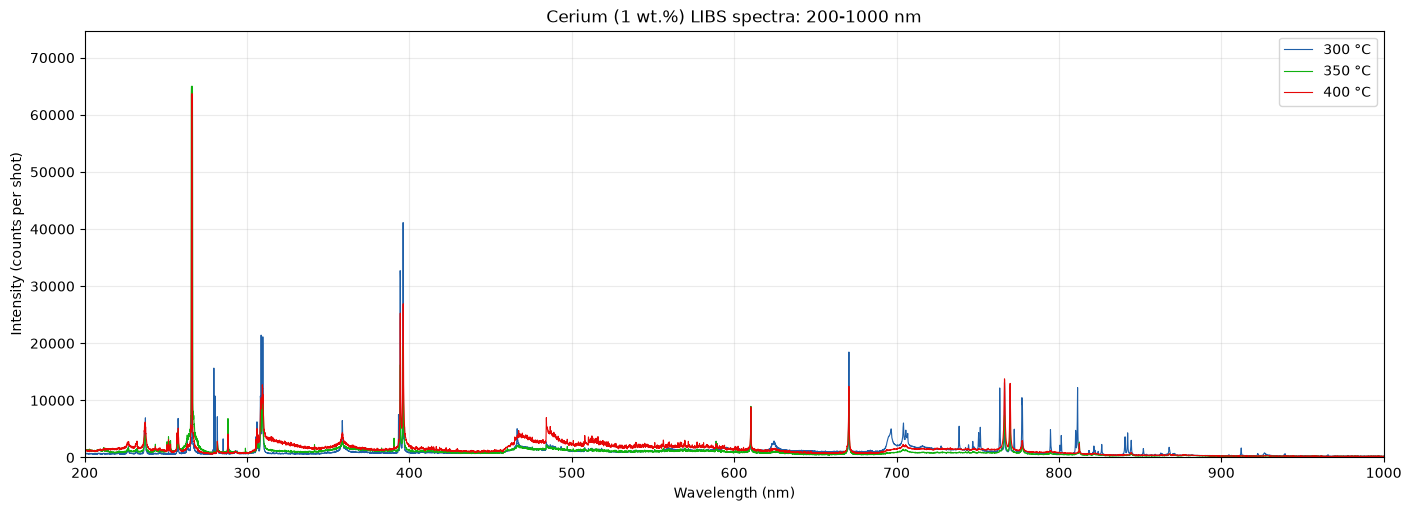

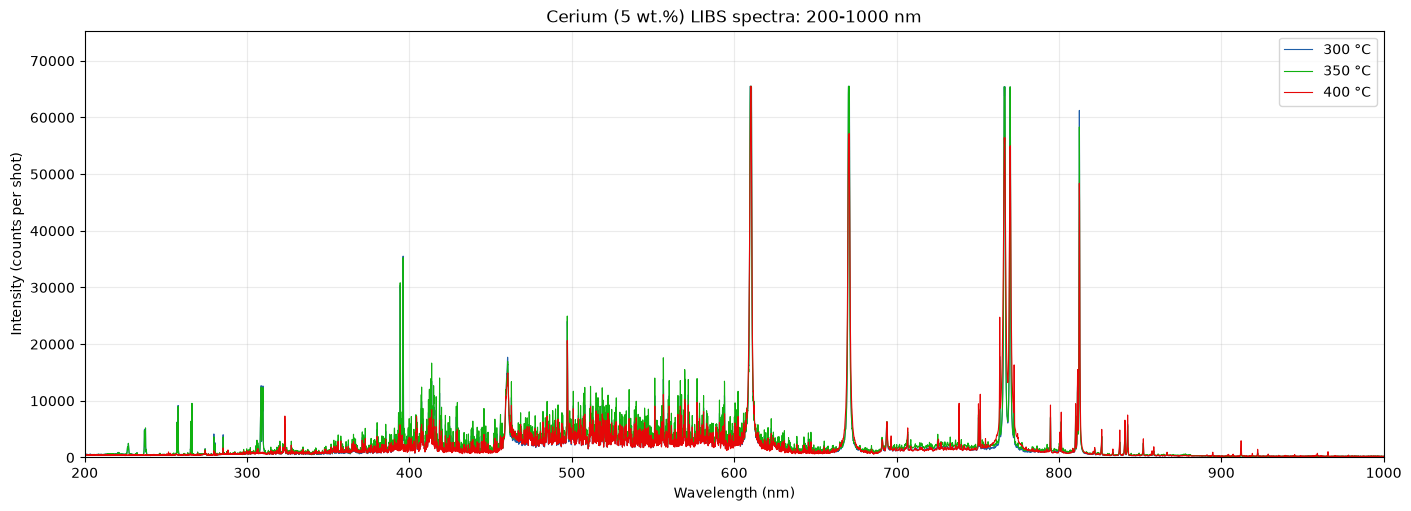

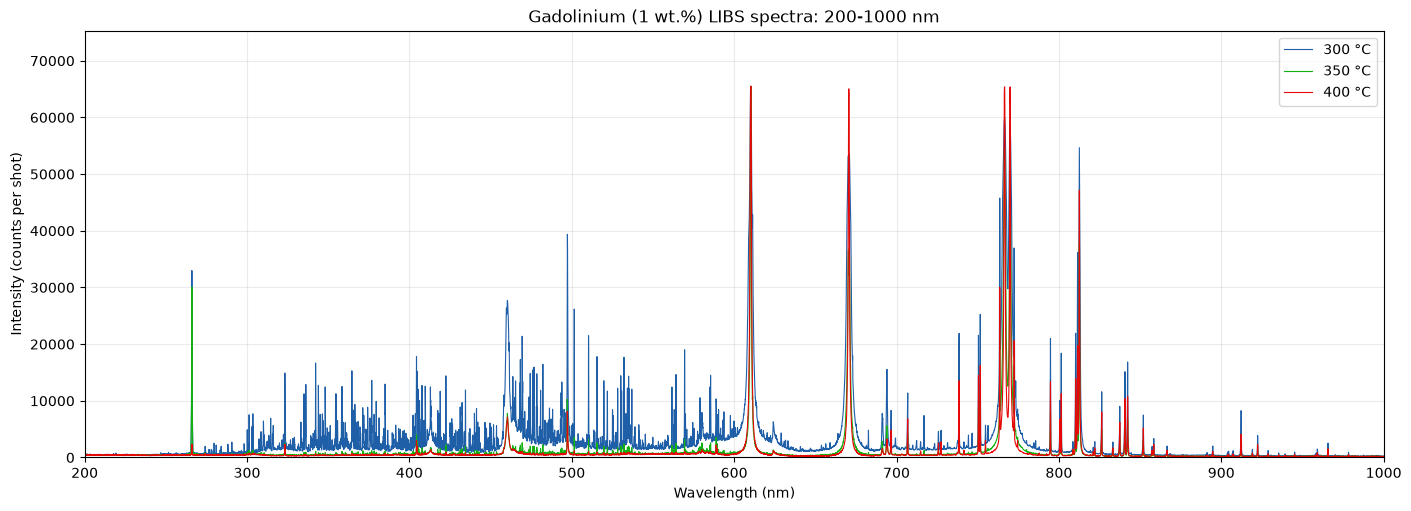

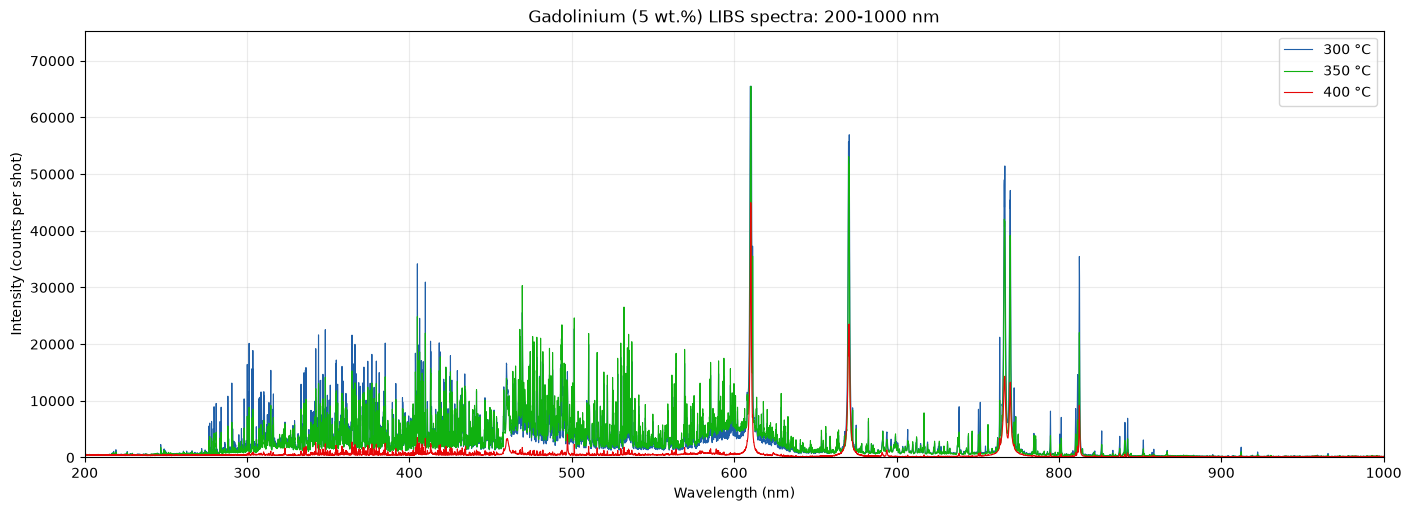

In [4]:
for sample in SAMPLES:
    overlay(sample, FULL_RANGE, zoom=False)

## Zoomed windows (4 images): Ce 390–480 nm, Gd 400–435 nm

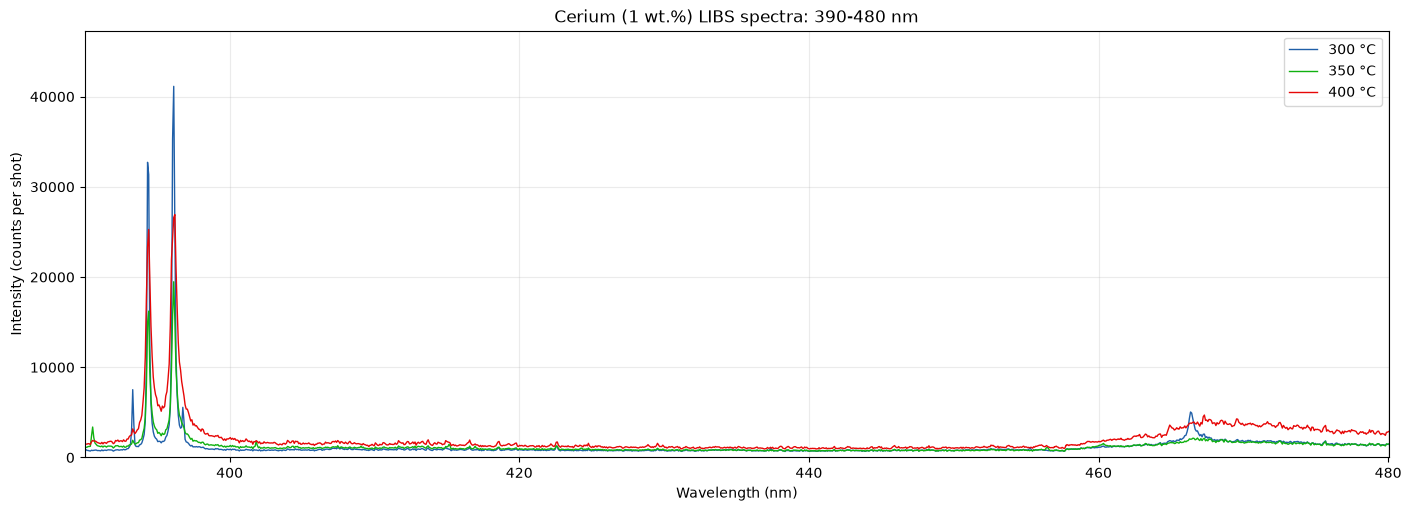

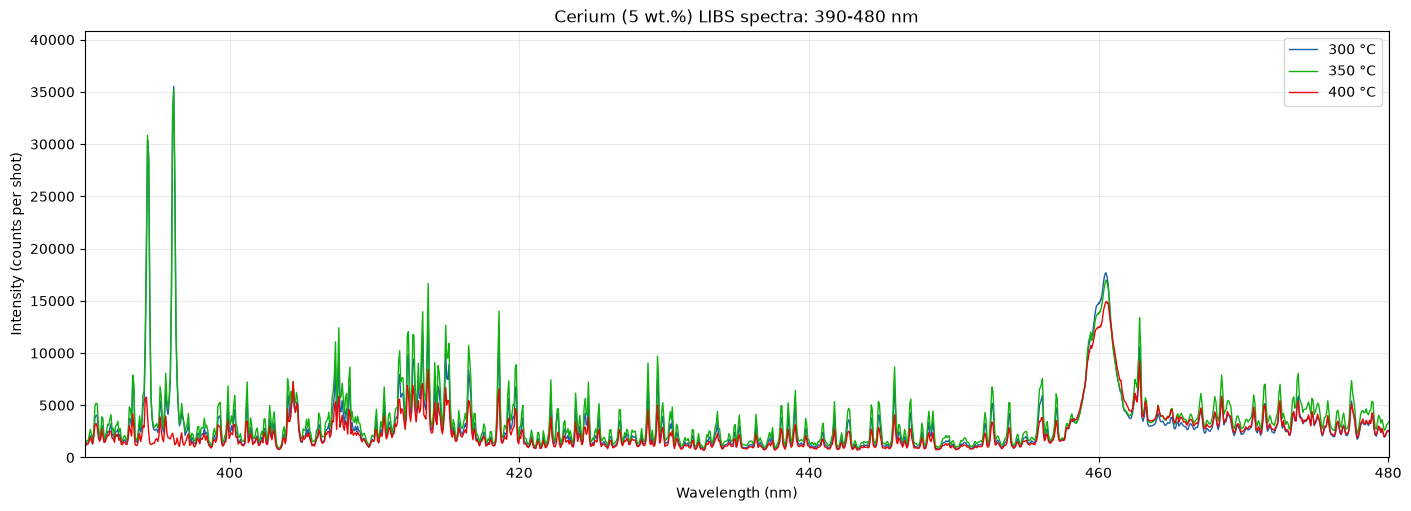

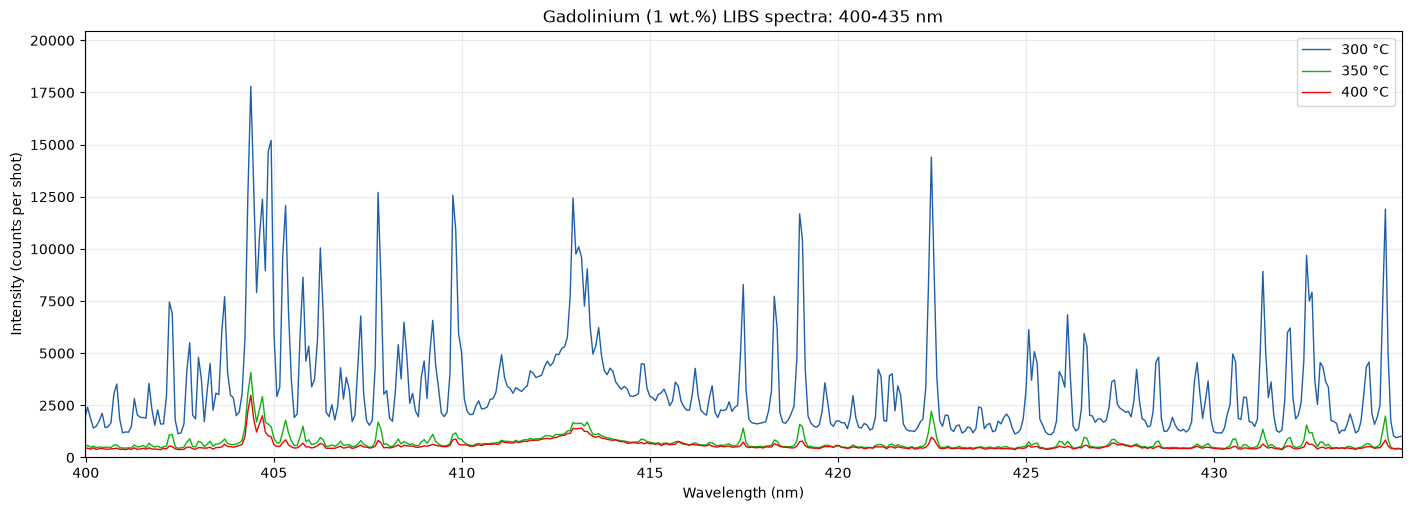

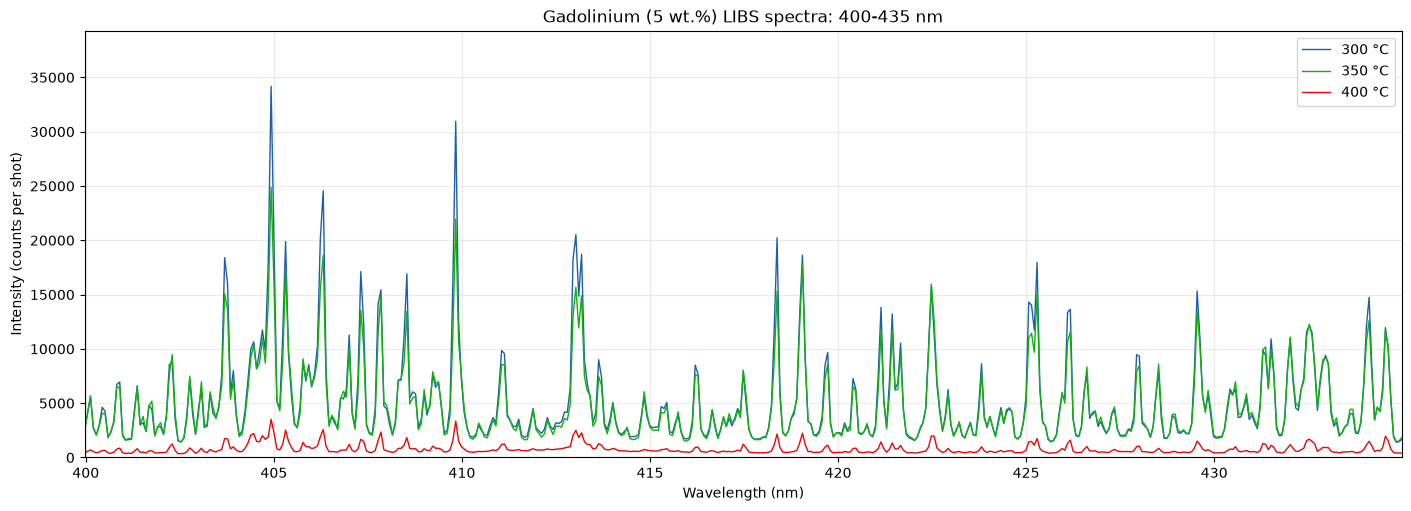

In [5]:
for sample in SAMPLES:
    overlay(sample, WINDOW[sample[:2]], zoom=True)